In [ ]:
#Import pandas, matplotlib with pyplot module for charting

import pandas as pd
import matplotlib.pyplot as plt

#Load + save file name

file = "Open_AI_Partners.xlsx"
%pip install openpyxl


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
#Load Sheet 1, which holds our specific data set. Kept getting errors/wrong counts, because I forgot I had made a pivot table within the sheet itself, 
# so limited the rows to 72 which is the last row of actual data

df = pd.read_excel(file, sheet_name="Sheet1", nrows=72)
df.info

<bound method DataFrame.info of    Date of Partnership Announcement  \
0                        2019-07-22   
1                        2022-10-25   
2                        2023-03-14   
3                        2023-07-13   
4                        2023-07-18   
..                              ...   
67                       2026-09-08   
68                       2026-09-23   
69                       2026-09-30   
70                       2026-09-30   
71                       2026-10-21   

                                         Partner Name  \
0                                           Microsoft   
1                                        Shutterstock   
2   Government of Iceland, Miðeind ehf and Almanna...   
3                               Associated Press (AP)   
4                   American Journalism Project (AJP)   
..                                                ...   
67                  American Journalism Project (AJP)   
68                                         

In [20]:
#Make a new column, "Year" by pulling out the year of the Date of Partnership column
df ["Year"] = df ["Date of Partnership Announcement"].dt.year

#Ran multiple random sample to make sure years got extracted correctly
df.sample(10)

,Date of Partnership Announcement,Partner Name,Partnership Sector,Hyperlink to Partnership Announcement,Location of Partnership,Recurring Partnership?,Partnership Involves Monetary Donation?,Size of Monetary Donation,Partnership Involves Licensing,Amount of Licensing Seats,Other Details (General Notes),Listed On,How Found,Partnership Type,Confidence,Classification reason,Agreement status,Second-sweep note,Year
3,2023-07-13,Associated Press (AP),Journalistic Institution,https://www.pbs.org/newshour/economy/chatgpt-c...,Not stated (AP is New York-based),No,No,—,Yes (content licensing),N/A – licenses part of AP's text archive (stor...,OpenAI licenses part of AP's text archive; AP ...,External source (not on openai.com),Your Airtable export,Partnership,Clear,OpenAI licenses part of AP's text archive and ...,Binding agreement,OpenAI acknowledgment: openai.com/index/global...,2023
22,2024-10-08,"Hearst (Houston Chronicle, San Francisco Chron...",Journalistic Institution,https://openai.com/index/hearst/,United States,Yes,No,—,Yes (content licensing),N/A – content partnership,Content partnership integrating 20+ Hearst mag...,Company Announcements page,Company Announcements page scrape; also in you...,Partnership,Clear,Hearst's newspaper and magazine content is int...,Binding agreement,NaN,2024
30,2025-02-14,Guardian Media Group,Journalistic Institution,https://openai.com/index/openai-and-guardian-m...,United Kingdom,No,No,—,Yes (content licensing + ChatGPT Enterprise),Not stated – ChatGPT Enterprise rolled out acr...,Strategic content partnership: Guardian report...,Company Announcements page,Company Announcements page scrape; also in you...,Partnership,Clear,Guardian reporting and extended summaries appe...,Not stated,NaN,2025
56,2026-02-02,Snowflake,Technology,https://openai.com/index/snowflake-partnership/,Global,Yes,No,$200 million multi-year partnership (commercia...,No,—,OpenAI models integrated into Snowflake Cortex...,Global Affairs page,Global Affairs page scrape,Partnership,Clear,"A multi-year, $200 million partnership bringin...",Not stated,NaN,2026
68,2026-09-23,Grab,Technology,https://openai.com/index/grab-openai-ai-skills...,"Singapore (launch); Thailand, Indonesia, Phili...",Yes,No,—,No,—,'GO Forward with AI' two-year regional skillin...,Global Affairs page,Global Affairs page scrape,Partnership,Clear,"OpenAI and Grab launched GO Forward with AI, a...",Not stated,"Re-read in Chrome on Oct 26, 2026 (after the b...",2026
54,2026-01-15,Merge Labs,Technology,https://openai.com/index/investing-in-merge-labs/,Not stated,No,No,OpenAI participates in Merge Labs' seed round ...,No,—,OpenAI invests in Merge Labs and will collabor...,Global Affairs page,Global Affairs page scrape,Partnership,Clear,OpenAI participates in Merge Labs' seed round ...,Not stated,NaN,2026
59,2026-05-11,Brookfield Asset Management,Finance,https://bam.brookfield.com/press-releases/broo...,Global,Yes,No,$500 million investment (not a donation),No,—,'Brookfield to Invest $500 Million in Strategi...,External source (not on openai.com),SEC EDGAR full-text search (company filing) → ...,Partnership,Clear,Brookfield 'has agreed to invest $500 million ...,Not stated,The sheet's link (bam.brookfield.com) now show...,2026
44,2025-10-06,AMD,Technology,https://openai.com/index/openai-amd-strategic-...,"Not stated (datelined Santa Clara, CA)",Yes,No,AMD issued OpenAI a warrant for up to 160 mill...,No,—,6 GW multi-generation agreement for AMD Instin...,Company Announcements page,Company Announcements page scrape,Partnership,Clear,A 'definitive agreement' for OpenAI to deploy ...,Binding agreement,NaN,2025
34,2025-04-22,The Washington Post,Journalistic Institution,https://openai.com/global-affairs/the-washingt...,"Washington, D.C., USA",No,No,—,Yes (content licensing),N/A – content partnership,Strategic content partnership: ChatGPT surface...,Global Affairs page,Global Affairs page scrape; also in your Airtable,Partnership,Clear,"The Washington Post's summaries, quotes

In [22]:
#Keeping only the 3 columns we need for the chart
df = df[["Year", "Partner Name", "Partnership Sector"]]

#Checking Table
df.sample(10)

,Year,Partner Name,Partnership Sector
10,2024,Stack Overflow,Technology
44,2025,AMD,Technology
36,2025,American Federation of Teachers (AFT) – Nation...,Nonprofit
52,2025,The Walt Disney Company,Entertainment
67,2026,American Journalism Project (AJP),Journalistic Institution
16,2024,"Vox Media (Vox, The Verge, Eater, New York Mag...",Journalistic Institution
7,2024,"Prisa Media (El País, Cinco Días, As, El HuffP...",Journalistic Institution
18,2024,Apple,Technology
56,2026,Snowflake,Technology
4,2023,American Journalism Project (AJP),Journalistic Institution


In [25]:
#Group everything by year & sector

partner_counts = df.groupby(["Year", "Partnership Sector"]).size()
partner_counts

Year  Partnership Sector      
2019  Technology                   1
2022  Technology                   1
2023  Government Agency            1
      Journalistic Institution     3
      Technology                   1
2024  Journalistic Institution    14
      Technology                   4
2025  Entertainment                1
      Finance                      2
      Government Agency            6
      Journalistic Institution     4
      Nonprofit                    2
      Technology                  14
2026  Finance                      2
      Government Agency            4
      Journalistic Institution     3
      Nonprofit                    2
      Technology                   7
dtype: int64

In [ ]:
#Make a list for both years and sectors
years = sorted(df["Year"].unique())
sectors = sorted(df["Partnership Sector"].unique())

years, sectors

([np.int32(2019),
  np.int32(2022),
  np.int32(2023),
  np.int32(2024),
  np.int32(2025),
  np.int32(2026)],
 ['Entertainment',
  'Finance',
  'Government Agency',
  'Journalistic Institution',
  'Nonprofit',
  'Technology'])

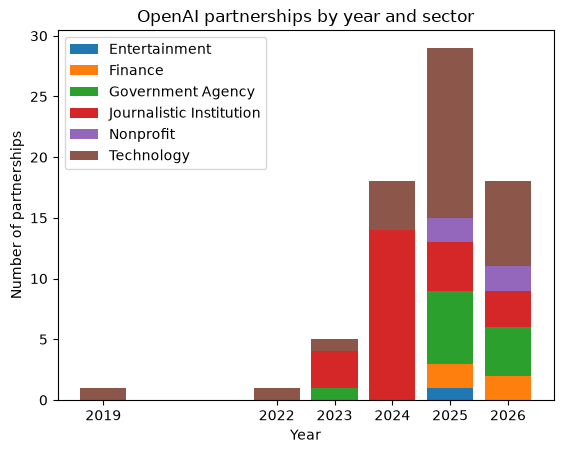

In [ ]:
#Making sure all bars start at 0
bottom = [0] * len(years)

#For loop to make stacked bar chart based on amount in each sector

for sector in sectors :
    
    heights = []
    for year in years:
        heights.append(partner_counts.get((year,sector), 0))
        
    #Making sure each new sector starts at the top of the last sector
    plt.bar (years, heights, bottom=bottom, label=sector)
    
    for i in range(len(years)):
        bottom[i] = bottom[i] + heights[i]
    
#Show a tick for each year
plt.xticks (years)

# Label the axes and give the chart a title
plt.xlabel("Year")
plt.ylabel("Number of partnerships")
plt.title("OpenAI partnerships by year and sector")

# Add a legend that shows which color is which sector (it uses the label= from plt.bar)
plt.legend()

# Display the chart
plt.show()
    